## 1. Import Necessary Libraries


In [154]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score

## 2. Import Dataset

In [155]:
wine_lib_data = load_wine()
wine_lib_data


{'data': array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
         1.065e+03],
        [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
         1.050e+03],
        [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
         1.185e+03],
        ...,
        [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
         8.350e+02],
        [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
         8.400e+02],
        [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
         5.600e+02]], shape=(178, 13)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [156]:
wine_lib_data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])

In [157]:
print(wine_lib_data['DESCR'])

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

In [158]:
wine_data = pd.DataFrame(wine_lib_data["data"], columns=wine_lib_data["feature_names"])
wine_data["target"] = wine_lib_data["target"]
wine_data

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


In [159]:
wine_data.sample(5)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
130,12.86,1.35,2.32,18.0,122.0,1.51,1.25,0.21,0.94,4.10,0.76,1.29,630.0,2
94,11.62,1.99,2.28,18.0,98.0,3.02,2.26,0.17,1.35,3.25,1.16,2.96,345.0,1
162,12.85,3.27,2.58,22.0,106.0,1.65,0.60,0.60,0.96,5.58,0.87,2.11,570.0,2
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
78,12.33,0.99,1.95,14.8,136.0,1.90,1.85,0.35,2.76,3.40,1.06,2.31,750.0,1


## 3. Data Understanding

In [160]:
wine_data.shape

(178, 14)

In [161]:
wine_data.isna().sum()

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

In [162]:
wine_data.dtypes

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

## 4. Model building

In [163]:
X = wine_data.drop(labels=["target"], axis=1)
print(X.shape)
X

(178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [164]:
std_scalar= StandardScaler()
X = std_scalar.fit_transform(X)

In [165]:
y = wine_data["target"]
print(y.shape)
y

(178,)


0      0
1      0
2      0
3      0
4      0
      ..
173    2
174    2
175    2
176    2
177    2
Name: target, Length: 178, dtype: int64

In [166]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y, shuffle=True)

In [167]:
print(f"Train: {X_train.shape, y_train.shape}")
print(f"Test {X_test.shape, y_test.shape}")

Train: ((142, 13), (142,))
Test ((36, 13), (36,))


# 5. Model Training || 6. Model Testing || 7. Model Evaluation

### When k = 3

In [168]:
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train, y_train)
y_pred_train = knn_model.predict(X_train)
print(f"Train Accuracy: {accuracy_score(y_train, y_pred_train)* 100:.3f}%")


Train Accuracy: 96.479%


### When k = 5

In [169]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred_train = knn_model.predict(X_train)
print(f"Train Accuracy: {accuracy_score(y_train, y_pred_train)* 100:.3f}%")


Train Accuracy: 97.887%


### When k = 7

In [170]:
knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(X_train, y_train)
y_pred_train = knn_model.predict(X_train)
print(f"Train Accuracy: {accuracy_score(y_train, y_pred_train)* 100:.3f}%")


Train Accuracy: 97.183%


### When k = 9

In [171]:
knn_model = KNeighborsClassifier(n_neighbors=9)
knn_model.fit(X_train, y_train)
y_pred_train = knn_model.predict(X_train)
print(f"Train Accuracy: {accuracy_score(y_train, y_pred_train)* 100:.3f}%")


Train Accuracy: 96.479%


### When k = 2

In [172]:
knn_model = KNeighborsClassifier(n_neighbors=2)
knn_model.fit(X_train, y_train)
y_pred_train = knn_model.predict(X_train)
print(f"Train Accuracy: {accuracy_score(y_train, y_pred_train)* 100:.3f}%")


Train Accuracy: 97.183%


### When k = 3

In [173]:
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train, y_train)
y_pred_train = knn_model.predict(X_train)
print(f"Train Accuracy: {accuracy_score(y_train, y_pred_train)* 100:.3f}%")


Train Accuracy: 96.479%


### How to choose the Optimal Number of Neighbours?

The below cell is by coach

In [174]:
# k_fold = KFold(n_splits=5, shuffle=True, random_state=42)
# cv_scores_mean = []

# for i in range(3, 52, 2):
#     knn_model = KNeighborsClassifier(n_neighbors=i)
#     knn_model.fit(X, y)
#     cv_score = cross_val_score(estimator=knn_model, X = X, y = y, cv=k_fold)
#     cv_scores_mean.append(cv_score.mean().round(4))
    
# # cv_scores_mean
# max(cv_scores_mean)
# cv_scores_mean.index(max(cv_scores_mean))

In [175]:
# cv_scores_mean.index(max(cv_scores_mean))

given by chatgpt

the below is with respct to the entire x  data

In [176]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_mean = []

k_values = range(3, 52, 2)

for k in k_values:

    knn_model = KNeighborsClassifier(n_neighbors=k)

    cv_score = cross_val_score(
        estimator=knn_model, X=X, y=y, cv=k_fold, scoring="accuracy"
    )

    cv_scores_mean.append(cv_score.mean())

best_index = cv_scores_mean.index(max(cv_scores_mean))

best_k = list(k_values)[best_index]

print("Best K:", best_k)
print("Best CV Accuracy:", cv_scores_mean[best_index])

Best K: 13
Best CV Accuracy: 0.9776190476190475


since i have start from 3 and step 2 so i need to follow the below formula to find my best $k$ value

$$
K = 3 + (13 \times 2) = 29
$$

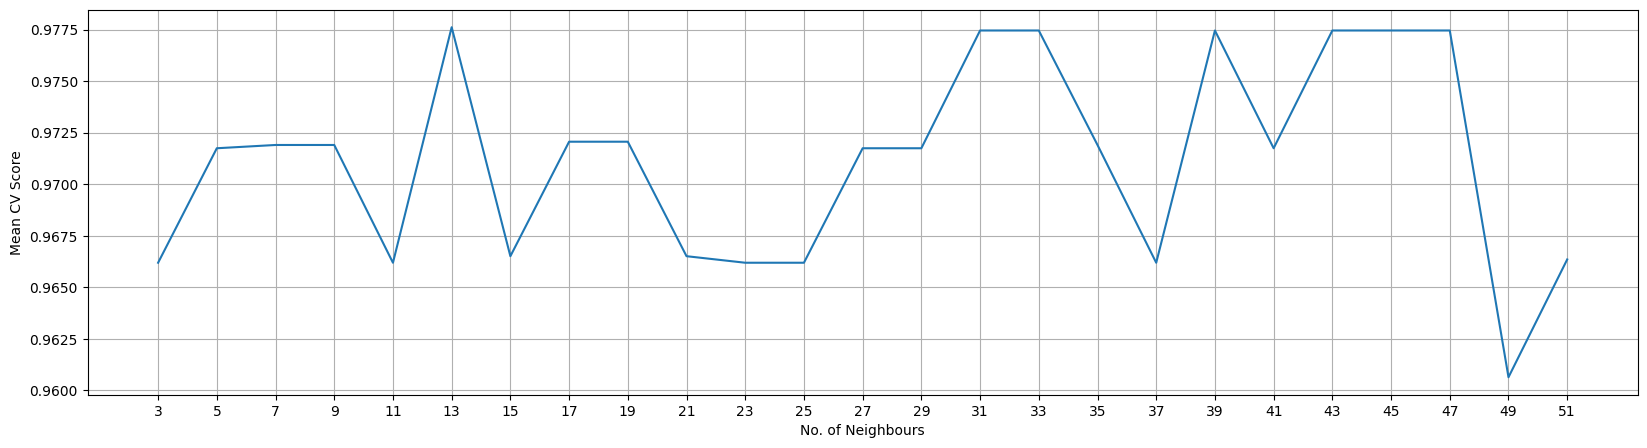

In [177]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 5))
plt.plot(k_values, cv_scores_mean)
plt.xticks(k_values)
plt.grid(True)
plt.xlabel("No. of Neighbours")
plt.ylabel("Mean CV Score")
plt.show()

This prediction is with respect to train data

In [178]:
knn_model = KNeighborsClassifier(n_neighbors=29)
knn_model.fit(X_train, y_train)
y_pred_train = knn_model.predict(X_train)
print(f"Train Accuracy: {accuracy_score(y_train, y_pred_train)* 100:.3f}%")

Train Accuracy: 97.183%
